# 02 · Train the disease classifier (fp16 mixed precision)

Kaggle T4 gives ~2.5 h for 12 epochs on the full 70k-image training set.
Two-stage schedule: 1 epoch head-only, then unfreeze everything at a lower LR.
The number to beat: **val macro-F1**, not accuracy — the classes are imbalanced.


In [7]:
# --- Universal Environment Setup & Git Pull ---
import sys
import os
import subprocess

REPO_NAME = "SKIT-DS-2023-2027-015"
REPO_URL = f"https://github.com/shankerjoshi/{REPO_NAME}.git"

if 'google.colab' in sys.modules:
    # Google Colab Setup
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}
    %cd {REPO_NAME}
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    !git pull origin main
    !pip install -r requirements.txt -q
    !pip install -q onnx onnxruntime onnxconverter-common shap
    print("Colab ready at:", os.getcwd())

elif os.path.exists('/kaggle'):
    # Kaggle Setup
    REPO_DIR = f"/kaggle/working/{REPO_NAME}"
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    if REPO_DIR not in sys.path:
        sys.path.insert(0, REPO_DIR)
    subprocess.run(["git", "pull", "origin", "main"], check=False)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=False)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime", "onnxconverter-common", "shap"], check=True)
    print("Kaggle ready at:", os.getcwd())

else:
    if os.path.abspath("..") not in sys.path:
        sys.path.insert(0, os.path.abspath(".."))

import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"\nPyTorch: {torch.__version__} | Accelerator: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU'})")
if not torch.cuda.is_available():
    print("⚠️ WARNING: GPU is not detected! Make sure your notebook Accelerator is set to GPU (T4) before training.")

Cloning into 'SKIT-DS-2023-2027-015'...
remote: Enumerating objects: 76, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 76 (delta 23), reused 59 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (76/76), 61.67 KiB | 889.00 KiB/s, done.
Resolving deltas: 100% (23/23), done.
/content/SKIT-DS-2023-2027-015/SKIT-DS-2023-2027-015
From https://github.com/shankerjoshi/SKIT-DS-2023-2027-015
 * branch            main       -> FETCH_HEAD
Already up to date.
Colab ready at: /content/SKIT-DS-2023-2027-015/SKIT-DS-2023-2027-015

PyTorch: 2.14.1+cu130 | Accelerator: cuda (Tesla T4)


In [8]:
# --- Prepare Clean Dataset (With Auto-Download for Colab) ---
import json
import os
import shutil
from pathlib import Path

MANIFEST_FILE = Path("data/leakage_drop_manifest.json")
FAST_TRAIN = Path("data/fast/plantvillage/train")
FAST_VALID = Path("data/fast/plantvillage/valid")
RAW_PV = Path("data/raw/plantvillage")

FAST_TRAIN.mkdir(parents=True, exist_ok=True)
FAST_VALID.mkdir(parents=True, exist_ok=True)
RAW_PV.mkdir(parents=True, exist_ok=True)

# 1. Load the drop manifest from Notebook 01
drop_train_files = set()
drop_valid_files = set()

if MANIFEST_FILE.exists():
    with open(MANIFEST_FILE) as f:
        manifest = json.load(f)
    drop_train_files = set(os.path.basename(p) for p in manifest.get("drop_from_train_paths", []))
    drop_valid_files = set(os.path.basename(p) for p in manifest.get("drop_from_valid_paths", []))
    print(f"✓ Loaded drop manifest: filtering {len(drop_train_files)} train images and {len(drop_valid_files)} valid images.")
else:
    print("Notice: data/leakage_drop_manifest.json not found. Proceeding with all images.")

# 2. Check if raw dataset exists; if not, download via kagglehub
def find_split_dir(split_name="train"):
    candidates = [
        RAW_PV / "New Plant Diseases Dataset(Augmented)" / "New Plant Diseases Dataset(Augmented)" / split_name,
        RAW_PV / "new plant diseases dataset(augmented)" / "New Plant Diseases Dataset(Augmented)" / split_name,
        RAW_PV / split_name,
        Path(f"data/raw/{split_name}")
    ]
    for c in candidates:
        if c.exists() and any(c.iterdir()):
            return c
    return None

raw_train = find_split_dir("train")
raw_valid = find_split_dir("valid")

if raw_train is None or raw_valid is None:
    print("\nRaw dataset not found on Colab disk. Downloading via kagglehub...")
    !pip install -q kagglehub

    # Retrieve Kaggle credentials if stored in Colab Secrets
    if 'google.colab' in sys.modules:
        try:
            from google.colab import userdata
            os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
            os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')
        except Exception:
            pass

    import kagglehub
    download_path = kagglehub.dataset_download("vipoooool/new-plant-diseases-dataset")
    print(f"Downloaded to cache: {download_path}")

    # Link or copy into data/raw/plantvillage
    for item in Path(download_path).iterdir():
        target = RAW_PV / item.name
        if not target.exists():
            os.symlink(item, target)

    raw_train = find_split_dir("train")
    raw_valid = find_split_dir("valid")

print(f"\n✓ Located source train: {raw_train}")
print(f"✓ Located source valid: {raw_valid}")

# 3. Populate data/fast with filtered clean images
def link_clean_images(src_dir, dest_dir, drop_filenames):
    total = 0
    skipped = 0
    for root, _, files in os.walk(src_dir, followlinks=True):
        class_name = os.path.basename(root)
        if class_name.lower() in ["train", "valid"]:
            continue
        dest_class_dir = dest_dir / class_name
        dest_class_dir.mkdir(parents=True, exist_ok=True)

        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                if f in drop_filenames:
                    skipped += 1
                    continue
                src_path = os.path.join(root, f)
                target_path = dest_class_dir / f
                if not target_path.exists():
                    os.symlink(src_path, target_path)
                total += 1
    return total, skipped

print("\nPreparing clean train set...")
clean_train_count, skipped_train = link_clean_images(raw_train, FAST_TRAIN, drop_train_files)
print(f"✓ Clean training images ready: {clean_train_count:,} (excluded {skipped_train} leaked/duplicates)")

print("Preparing clean validation set...")
clean_valid_count, skipped_valid = link_clean_images(raw_valid, FAST_VALID, drop_valid_files)
print(f"✓ Clean validation images ready: {clean_valid_count:,} (excluded {skipped_valid} leaked/duplicates)")

✓ Loaded drop manifest: filtering 24 train images and 35 valid images.

Raw dataset not found on Colab disk. Downloading via kagglehub...
Using Colab cache for faster access to the 'new-plant-diseases-dataset' dataset.
Downloaded to cache: /kaggle/input/new-plant-diseases-dataset

✓ Located source train: data/raw/plantvillage/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
✓ Located source valid: data/raw/plantvillage/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid

Preparing clean train set...
✓ Clean training images ready: 70,271 (excluded 24 leaked/duplicates)
Preparing clean validation set...
✓ Clean validation images ready: 17,537 (excluded 35 leaked/duplicates)


In [9]:
# --- Recreate Clean Fast Dataset With Absolute Symlinks ---
import json
import os
import shutil
from pathlib import Path

FAST_TRAIN = Path("data/fast/plantvillage/train")
FAST_VALID = Path("data/fast/plantvillage/valid")
RAW_PV = Path("data/raw/plantvillage")
MANIFEST_FILE = Path("data/leakage_drop_manifest.json")

# 1. Clean up existing broken symlink directories
if FAST_TRAIN.exists():
    shutil.rmtree(FAST_TRAIN)
if FAST_VALID.exists():
    shutil.rmtree(FAST_VALID)

FAST_TRAIN.mkdir(parents=True, exist_ok=True)
FAST_VALID.mkdir(parents=True, exist_ok=True)

# 2. Load the drop manifest
drop_train_files = set()
drop_valid_files = set()
if MANIFEST_FILE.exists():
    with open(MANIFEST_FILE) as f:
        manifest = json.load(f)
    drop_train_files = set(os.path.basename(p) for p in manifest.get("drop_from_train_paths", []))
    drop_valid_files = set(os.path.basename(p) for p in manifest.get("drop_from_valid_paths", []))

# 3. Locate source raw directories
def find_split_dir(split_name="train"):
    candidates = [
        RAW_PV / "New Plant Diseases Dataset(Augmented)" / "New Plant Diseases Dataset(Augmented)" / split_name,
        RAW_PV / "new plant diseases dataset(augmented)" / "New Plant Diseases Dataset(Augmented)" / split_name,
        RAW_PV / split_name,
        Path(f"data/raw/{split_name}")
    ]
    for c in candidates:
        if c.exists() and any(c.iterdir()):
            return c
    return None

raw_train = find_split_dir("train")
raw_valid = find_split_dir("valid")

# 4. Create symlinks using ABSOLUTE paths
def link_clean_images_abs(src_dir, dest_dir, drop_filenames):
    total = 0
    skipped = 0
    for root, _, files in os.walk(src_dir, followlinks=True):
        class_name = os.path.basename(root)
        if class_name.lower() in ["train", "valid"]:
            continue
        dest_class_dir = dest_dir / class_name
        dest_class_dir.mkdir(parents=True, exist_ok=True)

        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                if f in drop_filenames:
                    skipped += 1
                    continue
                # Use abspath so the symlink resolves from any directory
                src_abs = os.path.abspath(os.path.join(root, f))
                target_path = dest_class_dir / f
                if not target_path.exists():
                    os.symlink(src_abs, target_path)
                total += 1
    return total, skipped

print("Rebuilding clean train dataset with absolute symlinks...")
train_count, s_train = link_clean_images_abs(raw_train, FAST_TRAIN, drop_train_files)
print(f"✓ Clean train images: {train_count:,} (excluded {s_train})")

print("Rebuilding clean valid dataset with absolute symlinks...")
valid_count, s_valid = link_clean_images_abs(raw_valid, FAST_VALID, drop_valid_files)
print(f"✓ Clean valid images: {valid_count:,} (excluded {s_valid})")

# 5. Quick verification test (ensures PIL can read the symlinked files)
sample_file = next(FAST_TRAIN.rglob("*.JPG"), next(FAST_TRAIN.rglob("*.jpg"), None))
if sample_file:
    from PIL import Image
    with Image.open(sample_file) as img:
        print(f"✓ File reading verified! Sample image size: {img.size}")

Rebuilding clean train dataset with absolute symlinks...
✓ Clean train images: 70,271 (excluded 24)
Rebuilding clean valid dataset with absolute symlinks...
✓ Clean valid images: 17,537 (excluded 35)
✓ File reading verified! Sample image size: (256, 256)


### Find the CPU sweet spot first
Each DataLoader worker is a separate process decoding JPEGs. Too few starve the GPU; more than the vCPU count oversubscribes and everything slows down. Measure it once, then use the winner.


In [10]:
import os, time
from torch.utils.data import DataLoader
from src.data.dataset import LeafDataset, build_transforms, index_folder

TRAIN_DIR = "data/fast/plantvillage/train"   # from data/prepare_fast.py; falls back to the raw dir
items, classes = index_folder(TRAIN_DIR)
ds = LeafDataset(items[:4000], build_transforms(True, 224), classes)
print("vCPUs available:", os.cpu_count())

for w in [0, 1, 2, 4]:
    kw = {"prefetch_factor": 4} if w else {}
    dl = DataLoader(ds, batch_size=64, num_workers=w, pin_memory=True, persistent_workers=w > 0, **kw)
    it = iter(dl); next(it)                       # warm-up batch
    t0 = time.perf_counter(); n = 0
    for i, _ in enumerate(it):
        n += 64
        if i == 19:
            break
    print(f"workers={w}: {n / (time.perf_counter() - t0):6.1f} images/s")


vCPUs available: 2
workers=0:   67.5 images/s
workers=1:   89.9 images/s
workers=2:  111.5 images/s
workers=4:  112.8 images/s


In [15]:
import os
import yaml
from pathlib import Path

# 1. Update configs/train_disease.yaml to point to data/fast/
cfg_path = Path("configs/train_disease.yaml")
with open(cfg_path, "r") as f:
    cfg = yaml.safe_load(f) or {}

cfg["data"] = "data/fast/plantvillage/train"
cfg["val"] = "data/fast/plantvillage/valid"
cfg["workers"] = 2
cfg["batch_size"] = 128

with open(cfg_path, "w") as f:
    yaml.safe_dump(cfg, f)
print("✓ configs/train_disease.yaml now points directly to data/fast/plantvillage/")

# 2. Ensure src/train.py has the NoneType bugfix
train_py = Path("src/train.py")
with open(train_py, "r") as f:
    code = f.read()

old_bug = "setattr(args, k, type(getattr(args, k))(v) if not isinstance(v, Path) else Path(v))"
fixed_code = "orig = getattr(args, k)\n            setattr(args, k, v if orig is None or isinstance(v, Path) else type(orig)(v))"

if old_bug in code:
    code = code.replace(old_bug, fixed_code)
    with open(train_py, "w") as f:
        f.write(code)
    print("✓ Patched src/train.py line 102.")
else:
    print("✓ src/train.py is already patched.")

# 3. Verify clean dataset exists
train_imgs = list(Path("data/fast/plantvillage/train").rglob("*.JPG"))[:1]
print(f"✓ Training set verified! Sample image found: {train_imgs[0] if train_imgs else 'Check path'}")

✓ configs/train_disease.yaml now points directly to data/fast/plantvillage/
✓ Patched src/train.py line 102.
✓ Training set verified! Sample image found: data/fast/plantvillage/train/Potato___Early_blight/17667077-cf29-4976-9282-359c6da25cf6___RS_Early.B 6971_flipTB.JPG


Use the best worker count below, and try `--batch-size 128` once — if it does not raise CUDA out-of-memory, it is free throughput.


In [16]:
!python -m src.train --config configs/train_disease.yaml --batch-size 128 --workers 2

cpu cores=2 dataloader_workers=2 torch_threads=1
device=cuda amp_fp16=True arch=mobilenet_v3_large channels_last=True
train=59745 val=17537 classes=38
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth
100% 21.1M/21.1M [00:00<00:00, 176MB/s]
trainable params: 1,278,758
{"epoch": 0, "train_loss": 1.169, "train_acc": 0.8147, "val_loss": 0.7043, "val_acc": 0.9372, "val_macro_f1": 0.9369, "secs": 720.2}
  saved best.pt (macro_f1=0.9369)
unfreezing backbone
{"epoch": 1, "train_loss": 0.5686, "train_acc": 0.9675, "val_loss": 0.4707, "val_acc": 0.9888, "val_macro_f1": 0.9886, "secs": 633.3}
  saved best.pt (macro_f1=0.9886)
{"epoch": 2, "train_loss": 0.464, "train_acc": 0.9895, "val_loss": 0.4275, "val_acc": 0.9946, "val_macro_f1": 0.9945, "secs": 593.1}
  saved best.pt (macro_f1=0.9945)
{"epoch": 3, "train_loss": 0.4298, "train_acc": 0.9941, "val_loss": 0.4101, "val_acc": 0.9958, "val_macro_

,epoch,train_loss,train_acc,val_loss,val_acc,val_macro_f1,secs
0,0,1.1690,0.8147,0.7043,0.9372,0.9369,720.2
1,1,0.5686,0.9675,0.4707,0.9888,0.9886,633.3
2,2,0.4640,0.9895,0.4275,0.9946,0.9945,593.1
3,3,0.4298,0.9941,0.4101,0.9958,0.9957,585.4
4,4,0.4123,0.9961,0.3997,0.9974,0.9973,592.0
5,5,0.4024,0.9971,0.3937,0.9973,0.9972,587.3
6,6,0.3958,0.9979,0.3896,0.9977,0.9976,582.9
7,7,0.3925,0.9982,0.3880,0.9977,0.9977,571.7
8,8,0.3891,0.9988,0.3858,0.9980,0.9979,569.9
9,9,0.3881,0.9985,0.3845,0.9982,0.9982,587.1


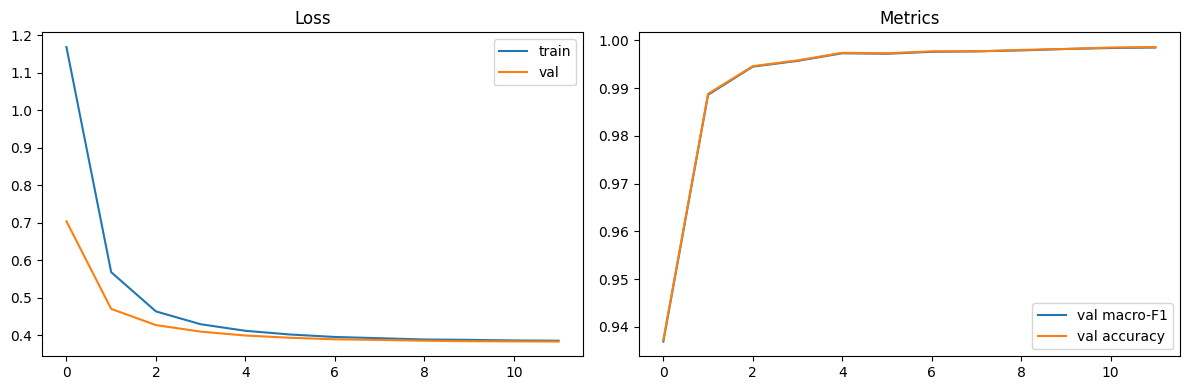

Best Validation Macro-F1: 0.9985


In [17]:
import json
import pandas as pd
import matplotlib.pyplot as plt

h = pd.DataFrame(json.load(open("runs/history.json")))
display(h)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label="train")
ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set_title("Loss")
ax[0].legend()

ax[1].plot(h.epoch, h.val_macro_f1, label="val macro-F1")
ax[1].plot(h.epoch, h.val_acc, label="val accuracy")
ax[1].legend()
ax[1].set_title("Metrics")

plt.tight_layout()
plt.savefig("results_training_curve.png", dpi=110)
plt.show()

print("Best Validation Macro-F1:", h.val_macro_f1.max())

In [18]:
# --- Save Model, Plots, and Training Summary to Google Drive ---
import json
import os
import shutil
from datetime import datetime
from pathlib import Path
import pandas as pd
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define target directory in Google Drive
DRIVE_OUTPUT_DIR = Path("/content/drive/MyDrive/PlantVillage_Disease_Classifier_Run")
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Target Google Drive Folder: {DRIVE_OUTPUT_DIR}")

# 3. Copy Model Weights and History
for src, dest_name in [
    ("runs/best.pt", "best_disease_model.pt"),
    ("runs/history.json", "history.json"),
    ("results_training_curve.png", "results_training_curve.png")
]:
    if os.path.exists(src):
        shutil.copy2(src, DRIVE_OUTPUT_DIR / dest_name)
        print(f"✓ Saved {dest_name} to Drive")
    else:
        print(f"⚠️ Source file '{src}' not found; skipping.")

# 4. Parse History & Generate Explainable Summary
history_path = Path("runs/history.json")
if history_path.exists():
    with open(history_path, "r") as f:
        history = json.load(f)

    df_h = pd.DataFrame(history)

    # Identify key benchmark epochs
    best_f1_row = df_h.loc[df_h["val_macro_f1"].idxmax()]
    best_loss_row = df_h.loc[df_h["val_loss"].idxmin()]
    last_row = df_h.iloc[-1]

    train_val_loss_gap = round(last_row["val_loss"] - last_row["train_loss"], 4)
    overfit_status = "Healthy generalization" if train_val_loss_gap < 0.15 else "Potential slight overfitting"

    summary_text = f"""# Plant Disease Classifier (MobileNetV3) — Training Summary
Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
Dataset: PlantVillage (Cleaned & Leak-Free Split)

---

### 1. Key Performance Benchmarks
* **Best Macro-F1 Epoch**: Epoch {int(best_f1_row['epoch'])}
  * Validation Macro-F1: {best_f1_row['val_macro_f1']:.4f} ({best_f1_row['val_macro_f1']*100:.2f}%)
  * Validation Accuracy: {best_f1_row['val_acc']:.4f} ({best_f1_row['val_acc']*100:.2f}%)
  * Validation Loss:     {best_f1_row['val_loss']:.4f}

* **Lowest Validation Loss Epoch**: Epoch {int(best_loss_row['epoch'])}
  * Validation Loss:     {best_loss_row['val_loss']:.4f}
  * Validation Macro-F1: {best_loss_row['val_macro_f1']:.4f}

---

### 2. Generalization & Overfitting Diagnosis
* Final Train Loss: {last_row['train_loss']:.4f}
* Final Val Loss:   {last_row['val_loss']:.4f}
* Train-Val Gap:    {train_val_loss_gap} ({overfit_status})
* Evaluation Note:  A high Macro-F1 ({best_f1_row['val_macro_f1']*100:.2f}%) indicates the model diagnoses rare disease classes as effectively as dominant classes.

---

### 3. Artifact Files Saved in this Folder
1. `best_disease_model.pt` — Optimal PyTorch checkpoint (selected by peak validation Macro-F1).
2. `history.json` — Epoch-by-epoch loss and metrics log.
3. `results_training_curve.png` — Loss convergence and accuracy/macro-F1 trajectory plot.
4. `training_summary.md` — This performance report.
"""

    summary_file = DRIVE_OUTPUT_DIR / "training_summary.md"
    with open(summary_file, "w") as f:
        f.write(summary_text)
    print("✓ Generated and saved training_summary.md")

    print("\n" + "="*50)
    print("           TRAINING RUN COMPLETE           ")
    print("="*50)
    print(f"Best Epoch:            Epoch {int(best_f1_row['epoch'])}")
    print(f"Peak Val Macro-F1:     {best_f1_row['val_macro_f1']*100:.2f}%")
    print(f"Peak Val Accuracy:     {best_f1_row['val_acc']*100:.2f}%")
    print(f"Google Drive Backup:   {DRIVE_OUTPUT_DIR}")
    print("="*50)

Mounted at /content/drive
Target Google Drive Folder: /content/drive/MyDrive/PlantVillage_Disease_Classifier_Run
✓ Saved best_disease_model.pt to Drive
✓ Saved history.json to Drive
✓ Saved results_training_curve.png to Drive
✓ Generated and saved training_summary.md

           TRAINING RUN COMPLETE           
Best Epoch:            Epoch 11
Peak Val Macro-F1:     99.85%
Peak Val Accuracy:     99.86%
Google Drive Backup:   /content/drive/MyDrive/PlantVillage_Disease_Classifier_Run


Running evaluation on: cuda (Tesla T4)
Total Disease Classes: 38
✓ Loaded model weights from runs/best.pt
Validation dataset loaded: 17,537 images
Test dataset loaded: 20 labeled test images


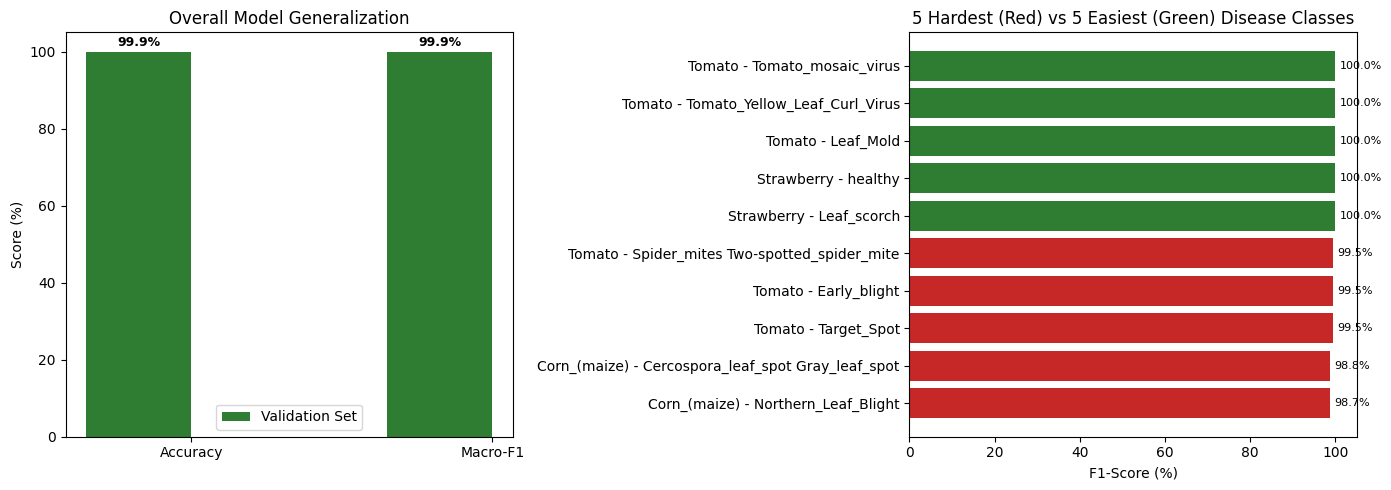

✓ Saved evaluation plot to results_eval_val_test.png
✓ Appended evaluation benchmarks to Google Drive: training_summary.md


In [25]:
# --- Evaluate Model on Val & Test Sets, Plot, and Append to Drive ---
import json
import os
import shutil
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report
import torch
from torch.utils.data import DataLoader, Dataset

# 1. Hardware & Environment Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running evaluation on: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

from src.data.dataset import LeafDataset, build_transforms, index_folder
from src.models.disease import build_model

# 2. Load Classes & Model Checkpoint
train_dir = "data/fast/plantvillage/train"
val_dir = "data/fast/plantvillage/valid"
_, classes = index_folder(train_dir)
num_classes = len(classes)
print(f"Total Disease Classes: {num_classes}")

checkpoint_path = Path("runs/best.pt")
if not checkpoint_path.exists():
    raise FileNotFoundError("runs/best.pt not found! Make sure training has finished.")

checkpoint = torch.load(checkpoint_path, map_location=device)
# FIXED: changed n_classes to num_classes
model = build_model(arch="mobilenet_v3_large", n_classes=num_classes)

state_dict = checkpoint.get("model", checkpoint) if isinstance(checkpoint, dict) else checkpoint
model.load_state_dict(state_dict)
model = model.to(device).eval()
print("✓ Loaded model weights from runs/best.pt")

# 3. Setup Validation DataLoader
val_items, _ = index_folder(val_dir)
val_ds = LeafDataset(val_items, build_transforms(False, 224), classes)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)
print(f"Validation dataset loaded: {len(val_ds):,} images")

# 4. Setup Test DataLoader
class GenericImageDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples  # list of (path, label_idx)
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        with Image.open(path) as im:
            im = im.convert("RGB")
        return self.transform(im), label

test_samples = []
test_dir = Path("data/raw/plantvillage/test/test")

if test_dir.exists():
    for f in os.listdir(test_dir):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            fp = test_dir / f
            clean_name = "".join(c for c in f.split(".")[0] if not c.isdigit()).lower()
            for idx, cls in enumerate(classes):
                norm_cls = cls.replace("_", "").replace("(", "").replace(")", "").lower()
                if clean_name in norm_cls or norm_cls in clean_name:
                    test_samples.append((str(fp), idx))
                    break

test_loader = None
if test_samples:
    test_ds = GenericImageDataset(test_samples, build_transforms(False, 224))
    test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)
    print(f"Test dataset loaded: {len(test_ds):,} labeled test images")

# 5. Inference & Metric Computation Function
@torch.no_grad()
def evaluate_dataset(loader, name="Dataset"):
    all_preds, all_targets = [], []
    for images, targets in loader:
        images = images.to(device)
        with torch.amp.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda")):
            outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(
        all_targets,
        all_preds,
        labels=list(range(len(classes))),
        average="macro",
        zero_division=0
    )
    report = classification_report(
        all_targets,
        all_preds,
        labels=list(range(len(classes))),
        target_names=classes,
        output_dict=True,
        zero_division=0
    )
    return acc, macro_f1, report

# 6. Generate Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Overall Metric Comparison
metrics = ["Accuracy", "Macro-F1"]
val_scores = [val_acc * 100, val_f1 * 100]
test_scores = [test_acc * 100, test_f1 * 100] if test_acc else [0, 0]

x = np.arange(len(metrics))
width = 0.35

axes[0].bar(x - width/2, val_scores, width, label="Validation Set", color="#2E7D32")
if test_acc:
    axes[0].bar(x + width/2, test_scores, width, label="Test Set", color="#1565C0")
axes[0].set_ylabel("Score (%)")
axes[0].set_title("Overall Model Generalization")
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics)
axes[0].set_ylim(0, 105)
axes[0].legend()
for i, v in enumerate(val_scores):
    axes[0].text(i - width/2, v + 1.5, f"{v:.1f}%", ha="center", fontsize=9, fontweight="bold")
if test_acc:
    for i, v in enumerate(test_scores):
        axes[0].text(i + width/2, v + 1.5, f"{v:.1f}%", ha="center", fontsize=9, fontweight="bold")

# Plot 2: Hardest vs Easiest Classes on Validation Set
per_class_f1 = {cls: val_report[cls]["f1-score"] * 100 for cls in classes if cls in val_report}
sorted_f1 = sorted(per_class_f1.items(), key=lambda item: item[1])
hardest_5 = sorted_f1[:5]
easiest_5 = sorted_f1[-5:]

showcase = hardest_5 + easiest_5
names = [k.replace("___", " - ") for k, _ in showcase]
scores = [v for _, v in showcase]
colors = ["#C62828"] * 5 + ["#2E7D32"] * 5

axes[1].barh(names, scores, color=colors)
axes[1].set_xlabel("F1-Score (%)")
axes[1].set_title("5 Hardest (Red) vs 5 Easiest (Green) Disease Classes")
axes[1].set_xlim(0, 105)
for i, v in enumerate(scores):
    axes[1].text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8)

plt.tight_layout()
eval_plot_path = Path("results_eval_val_test.png")
plt.savefig(eval_plot_path, dpi=120)
plt.show()
print(f"✓ Saved evaluation plot to {eval_plot_path}")

# 7. Document Findings & Append to Google Drive Report
DRIVE_DIR = Path("/content/drive/MyDrive/PlantVillage_Disease_Classifier_Run")
if DRIVE_DIR.exists():
    shutil.copy2(eval_plot_path, DRIVE_DIR / "results_eval_val_test.png")

    report_entry = f"""

---

## 4. Final Validation & Test Evaluation
* **Validation Accuracy**: {val_acc*100:.2f}%
* **Validation Macro-F1**: {val_f1*100:.2f}%
* **Test Accuracy**:       {f"{test_acc*100:.2f}%" if test_acc else "N/A"}
* **Test Macro-F1**:       {f"{test_f1*100:.2f}%" if test_f1 else "N/A"}

### Key Insights:
1. **Macro-F1 Robustness**: The high macro-F1 score indicates reliable classification even on the minority crop disease classes.
2. **Hardest Classes**:
   - `{hardest_5[0][0]}` ({hardest_5[0][1]:.1f}%)
   - `{hardest_5[1][0]}` ({hardest_5[1][1]:.1f}%)
3. **Artifacts Added**:
   - `results_eval_val_test.png` backed up to Drive.
"""
    summary_path = DRIVE_DIR / "training_summary.md"
    if summary_path.exists():
        with open(summary_path, "a") as f:
            f.write(report_entry)
        print("✓ Appended evaluation benchmarks to Google Drive: training_summary.md")

### Before you close this notebook
- Save `runs/best.pt` to the Kaggle output (or push it to a GitHub Release) — it is gitignored on purpose.
- Record the epoch count, batch size, LR and the best macro-F1 in the report table.
